# Question 1: Identify Data Quality Issues 

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset('iris')

In [3]:
df.head(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [4]:
df.shape

(150, 5)

In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [8]:
df.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

In [9]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [10]:
df.duplicated().sum()

1

In [11]:
df[df.duplicated()]

,sepal_length,sepal_width,petal_length,petal_width,species
142,5.8,2.7,5.1,1.9,virginica


# Question 2: Handle Missing Values & Duplicates

In [12]:
df[['sepal_length', 'sepal_width', 
   'petal_length', 'petal_width']].agg(
    ['mean', 'median', 'min', 'max']
)

,sepal_length,sepal_width,petal_length,petal_width
mean,5.843333,3.057333,3.758,1.199333
median,5.800000,3.000000,4.350,1.300000
min,4.300000,2.000000,1.000,0.100000
max,7.900000,4.400000,6.900,2.500000


In [13]:
grouped = df.groupby('species')

In [14]:
df.groupby('species').size()

species
setosa        50
versicolor    50
virginica     50
dtype: int64

In [15]:
df.groupby('species')[['sepal_length', 'petal_length']].mean()

,sepal_length,petal_length
species,,
setosa,5.006,1.462
versicolor,5.936,4.260
virginica,6.588,5.552


In [18]:
avg_petal = df.groupby('species')['petal_length'].mean()

print(avg_petal)
print("Highest average petal length:",avg_petal.idxmax())

species
setosa        1.462
versicolor    4.260
virginica     5.552
Name: petal_length, dtype: float64
Highest average petal length: virginica


In [19]:
df[df['petal_length'] > 5.0]

,sepal_length,sepal_width,petal_length,petal_width,species
83,6.0,2.7,5.1,1.6,versicolor
100,6.3,3.3,6.0,2.5,virginica
101,5.8,2.7,5.1,1.9,virginica
102,7.1,3.0,5.9,2.1,virginica
103,6.3,2.9,5.6,1.8,virginica
104,6.5,3.0,5.8,2.2,virginica
105,7.6,3.0,6.6,2.1,virginica
107,7.3,2.9,6.3,1.8,virginica
108,6.7,2.5,5.8,1.8,virginica
109,7.2,3.6,6.1,2.5,virginica


# Question 3: Univariate EDA

Text(0, 0.5, 'Frequency')

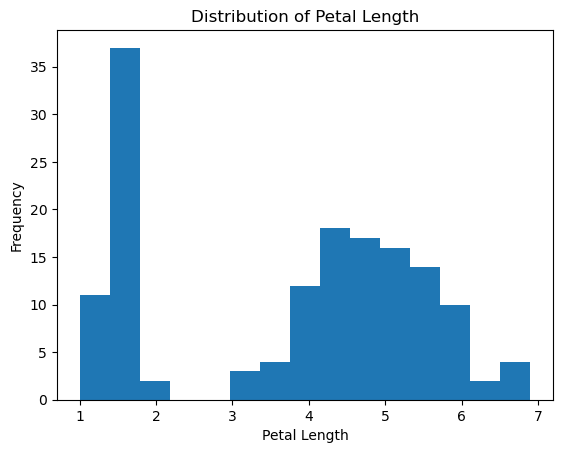

In [21]:
plt.hist(df['petal_length'], bins=15)

plt.title('Distribution of Petal Length')
plt.xlabel('Petal Length')
plt.ylabel('Frequency')

Text(0, 0.5, 'Petal Length')

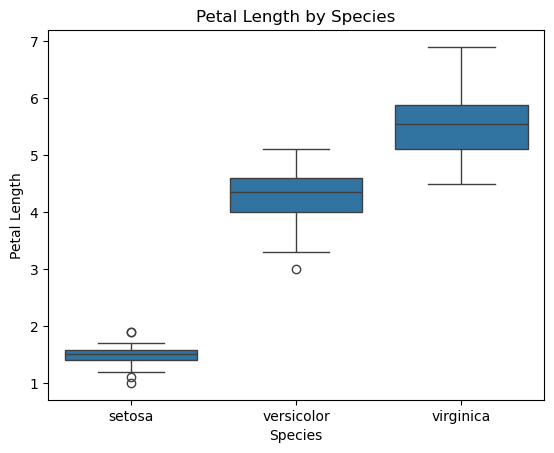

In [22]:
sns.boxplot(x='species', y='petal_length', data=df)

plt.title('Petal Length by Species')
plt.xlabel('Species')
plt.ylabel('Petal Length')

Text(0, 0.5, 'Petal Length')

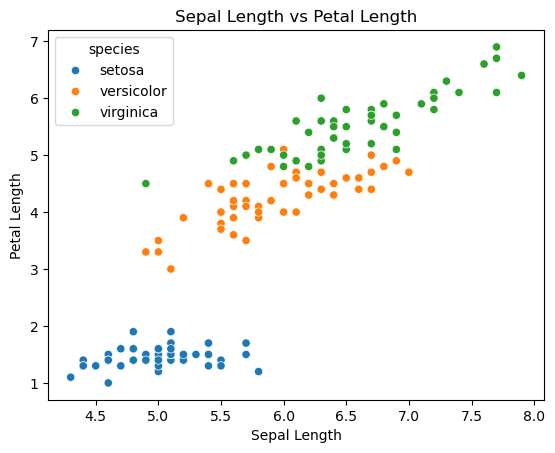

In [24]:
sns.scatterplot(x='sepal_length',y='petal_length',data=df,hue='species')

plt.title('Sepal Length vs Petal Length')
plt.xlabel('Sepal Length')
plt.ylabel('Petal Length')

Two meaningfull Observations

1. Virginica generally has the largest petel lengths
2. Flower with larger petal length generally have larger sepal length